In [1]:
import os, time, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
DEVICE = ("mps" if torch.backends.mps.is_available()
          else "cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
os.makedirs("models", exist_ok=True); os.makedirs("results", exist_ok=True)

def scores(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred),
            "roc_auc": roc_auc_score(y, p), "fpr": fp / (fp + tn),
            "fp": int(fp), "fn": int(fn)}

def recall_at_fpr(y, p, target=0.01):
    fpr, tpr, _ = roc_curve(y, p)
    return tpr[fpr <= target].max()

Device: mps


In [2]:
def load(mode):
    d = f"../data/features/{mode}"
    X_tr, X_va = np.load(f"{d}/X_train_chars.npy"), np.load(f"{d}/X_val_chars.npy")
    y_tr, y_va = np.load(f"{d}/y_train.npy"), np.load(f"{d}/y_val.npy")
    assert len(X_tr) == len(y_tr) and len(X_va) == len(y_va)
    n_vocab = int(max(X_tr.max(), X_va.max())) + 1
    return X_tr, y_tr, X_va, y_va, n_vocab


class CharCNN(nn.Module):
    """Embedding -> parallel Conv1d (k=3,5,7) -> global max pool -> MLP -> 1 logit."""
    def __init__(self, n_vocab, emb=32, filters=128, kernels=(3, 5, 7), hidden=64, drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, emb, padding_idx=0)
        self.convs = nn.ModuleList(nn.Conv1d(emb, filters, k, padding=k // 2) for k in kernels)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(filters * len(kernels), hidden),
                                  nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):
        mask = (x != 0).unsqueeze(1)                       # (B, 1, L): True on real characters
        h = self.emb(x).transpose(1, 2)                    # (B, emb, L)
        # ReLU output is >= 0, so zeroing padded positions excludes them from the max.
        pooled = [torch.relu(c(h)).masked_fill(~mask, 0).amax(dim=2) for c in self.convs]
        return self.head(torch.cat(pooled, dim=1)).squeeze(1)


class CharBiLSTM(nn.Module):
    """Optional comparison: Embedding -> BiLSTM(64) -> Linear."""
    def __init__(self, n_vocab, emb=32, hidden=64, drop=0.5):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, emb, padding_idx=0)
        self.lstm = nn.LSTM(emb, hidden, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(2 * hidden, 1))

    def forward(self, x):
        lengths = (x != 0).sum(1).clamp(min=1).cpu()
        packed = nn.utils.rnn.pack_padded_sequence(self.emb(x), lengths,
                                                   batch_first=True, enforce_sorted=False)
        _, (h, _) = self.lstm(packed)                      # h: (2, B, hidden), fwd + bwd final states
        return self.head(torch.cat([h[0], h[1]], dim=1)).squeeze(1)

In [3]:
@torch.no_grad()
def predict(model, X, bs=2048):
    model.eval()
    out = [torch.sigmoid(model(torch.from_numpy(X[i:i + bs]).long().to(DEVICE))).cpu()
           for i in range(0, len(X), bs)]
    return torch.cat(out).numpy()


def train(model, X_tr, y_tr, X_va, y_va, epochs=20, patience=3, lr=1e-3, bs=256):
    model.to(DEVICE)
    dl = DataLoader(TensorDataset(torch.from_numpy(X_tr).long(),
                                  torch.from_numpy(y_tr).float()),
                    batch_size=bs, shuffle=True)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.BCEWithLogitsLoss()
    best_auc, best_state, bad, history = -1, None, 0, []

    for ep in range(1, epochs + 1):
        model.train(); t0, total = time.time(), 0.0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step()
            total += loss.item() * len(xb)

        p = predict(model, X_va)
        auc, f1 = roc_auc_score(y_va, p), f1_score(y_va, (p >= 0.5).astype(int))
        history.append({"epoch": ep, "train_loss": total / len(X_tr), "val_auc": auc, "val_f1": f1})
        print(f"epoch {ep:2d}  loss {total / len(X_tr):.4f}  val AUC {auc:.4f}  "
              f"val F1 {f1:.4f}  ({time.time() - t0:.0f}s)")

        if auc > best_auc:                                 # early stopping on val ROC-AUC
            best_auc, best_state, bad = auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                print(f"stopping: no val AUC gain for {patience} epochs")
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

In [4]:
rows, probs, histories = [], {}, {}
for mode in ["host", "url"]:
    X_tr, y_tr, X_va, y_va, n_vocab = load(mode)
    torch.manual_seed(SEED)
    model = CharCNN(n_vocab)
    print(f"\n=== {mode} mode: {sum(p.numel() for p in model.parameters()):,} parameters ===")
    model, hist = train(model, X_tr, y_tr, X_va, y_va)

    p = predict(model, X_va)
    torch.save(model.state_dict(), f"../models/{mode}_cnn.pt")
    np.save(f"../results/val_probs_{mode}_cnn.npy", p)
    hist.to_csv(f"../results/history_{mode}_cnn.csv", index=False)
    rows.append({"mode": mode, "model": "cnn", **scores(y_va, p),
                 "recall@1%fpr": recall_at_fpr(y_va, p)})
    probs[mode], histories[mode] = p, hist


=== host mode: 87,809 parameters ===
epoch  1  loss 0.4051  val AUC 0.8913  val F1 0.7647  (14s)
epoch  2  loss 0.3454  val AUC 0.9005  val F1 0.7757  (11s)
epoch  3  loss 0.3317  val AUC 0.9071  val F1 0.8015  (11s)
epoch  4  loss 0.3211  val AUC 0.9108  val F1 0.8047  (12s)
epoch  5  loss 0.3146  val AUC 0.9118  val F1 0.8058  (12s)
epoch  6  loss 0.3091  val AUC 0.9139  val F1 0.8071  (12s)
epoch  7  loss 0.3042  val AUC 0.9145  val F1 0.8111  (11s)
epoch  8  loss 0.3012  val AUC 0.9154  val F1 0.8087  (10s)
epoch  9  loss 0.2976  val AUC 0.9169  val F1 0.8147  (11s)
epoch 10  loss 0.2944  val AUC 0.9168  val F1 0.8140  (11s)
epoch 11  loss 0.2926  val AUC 0.9174  val F1 0.8164  (11s)
epoch 12  loss 0.2896  val AUC 0.9181  val F1 0.8174  (12s)
epoch 13  loss 0.2879  val AUC 0.9179  val F1 0.8195  (12s)
epoch 14  loss 0.2851  val AUC 0.9181  val F1 0.8143  (12s)
epoch 15  loss 0.2835  val AUC 0.9183  val F1 0.8171  (12s)
epoch 16  loss 0.2818  val AUC 0.9185  val F1 0.8188  (12s)
ep

In [7]:
base = pd.read_csv("../results/phase5_baselines.csv")
table = pd.concat([base, pd.DataFrame(rows)], ignore_index=True)
table = table[["mode", "model", "precision", "recall", "f1", "roc_auc", "fpr", "recall@1%fpr"]]
table.to_csv("../results/phase6_vs_baselines.csv", index=False)
print(table.sort_values(["mode", "roc_auc"]).round(4).to_string(index=False))

mode    model  precision  recall     f1  roc_auc    fpr  recall@1%fpr
host   lr_lex     0.9097  0.6595 0.7647   0.8568 0.0406        0.5757
host   rf_lex     0.9270  0.6605 0.7714   0.8586 0.0322        0.6123
host lr_tfidf     0.9132  0.7120 0.8002   0.9116 0.0420        0.6247
host      cnn     0.9496  0.7185 0.8180   0.9196 0.0236        0.6824
 url lr_tfidf     0.9662  0.7973 0.8737   0.9429 0.0208        0.7757
 url      cnn     0.9781  0.8024 0.8816   0.9470 0.0134        0.7944
 url   rf_lex     0.9989  0.9952 0.9970   0.9986 0.0008        0.9965
 url   lr_lex     0.9993  0.9927 0.9960   0.9986 0.0005        0.9958


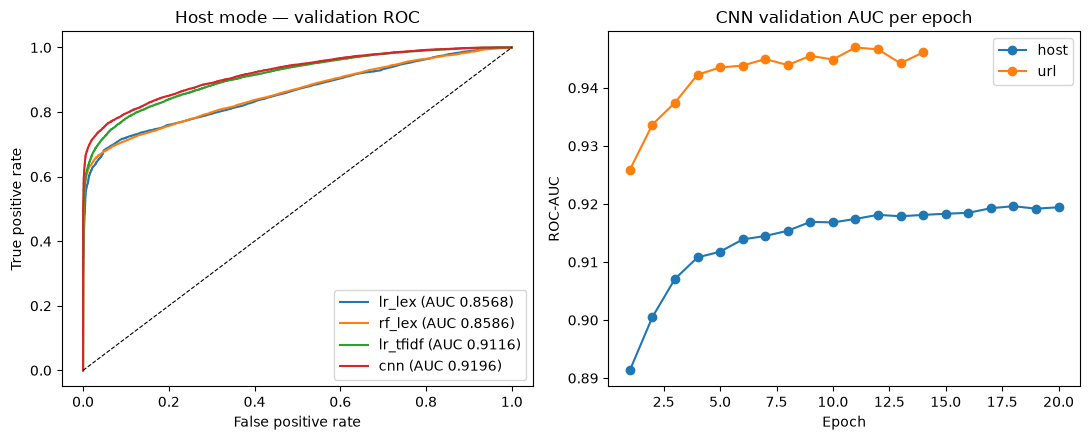

In [9]:
y_va_host = np.load("../data/features/host/y_val.npy")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name in ["lr_lex", "rf_lex", "lr_tfidf", "cnn"]:
    p = np.load(f"../results/val_probs_host_{name}.npy")
    fpr, tpr, _ = roc_curve(y_va_host, p)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_va_host, p):.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(title="Host mode — validation ROC", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend(loc="lower right")
for mode, h in histories.items():
    axes[1].plot(h["epoch"], h["val_auc"], marker="o", label=mode)
axes[1].set(title="CNN validation AUC per epoch", xlabel="Epoch", ylabel="ROC-AUC")
axes[1].legend()
plt.tight_layout(); plt.savefig("../results/phase6_cnn.png", dpi=150); plt.show()

In [11]:
X_tr, y_tr, X_va, y_va, n_vocab = load("host")
torch.manual_seed(SEED)
lstm = CharBiLSTM(n_vocab)
print(f"BiLSTM: {sum(p.numel() for p in lstm.parameters()):,} parameters")
lstm, lstm_hist = train(lstm, X_tr, y_tr, X_va, y_va)
p = predict(lstm, X_va)
torch.save(lstm.state_dict(), "../models/host_bilstm.pt")
np.save("../results/val_probs_host_bilstm.npy", p)
print({k: round(v, 4) for k, v in {**scores(y_va, p), "recall@1%fpr": recall_at_fpr(y_va, p)}.items()})

BiLSTM: 51,585 parameters
epoch  1  loss 0.4051  val AUC 0.8812  val F1 0.7622  (53s)
epoch  2  loss 0.3468  val AUC 0.8934  val F1 0.7893  (53s)
epoch  3  loss 0.3361  val AUC 0.8993  val F1 0.7920  (53s)
epoch  4  loss 0.3288  val AUC 0.9019  val F1 0.7901  (53s)
epoch  5  loss 0.3236  val AUC 0.9044  val F1 0.7964  (52s)
epoch  6  loss 0.3188  val AUC 0.9070  val F1 0.8019  (53s)
epoch  7  loss 0.3146  val AUC 0.9071  val F1 0.7939  (52s)
epoch  8  loss 0.3116  val AUC 0.9099  val F1 0.7994  (53s)
epoch  9  loss 0.3068  val AUC 0.9105  val F1 0.7987  (52s)
epoch 10  loss 0.3040  val AUC 0.9124  val F1 0.8034  (53s)
epoch 11  loss 0.3001  val AUC 0.9107  val F1 0.7956  (53s)
epoch 12  loss 0.2960  val AUC 0.9123  val F1 0.8092  (53s)
epoch 13  loss 0.2930  val AUC 0.9121  val F1 0.8036  (53s)
stopping: no val AUC gain for 3 epochs
{'precision': 0.9512, 'recall': 0.6954, 'f1': 0.8034, 'roc_auc': 0.9124, 'fpr': np.float64(0.0221), 'fp': 447, 'fn': 3821, 'recall@1%fpr': np.float64(0.660

In [13]:
import numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, roc_curve

d = "../data/features/url"
lex_tr = pd.read_csv(f"{d}/lex_train.csv")
lex_va = pd.read_csv(f"{d}/lex_val.csv")
y_tr   = np.load(f"{d}/y_train.npy")
y_va   = np.load(f"{d}/y_val.npy")
assert "is_https" in lex_tr.columns

def recall_at_fpr(y, p, target=0.01):
    fpr, tpr, _ = roc_curve(y, p)
    return tpr[fpr <= target].max()

for drop in [[], ["is_https"], ["is_https", "path_len"]]:
    rf = RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)
    rf.fit(lex_tr.drop(columns=drop), y_tr)
    p = rf.predict_proba(lex_va.drop(columns=drop))[:, 1]
    print(f"dropped {str(drop):28s} f1 {f1_score(y_va, (p >= 0.5).astype(int)):.4f}  "
          f"roc_auc {roc_auc_score(y_va, p):.4f}  recall@1%fpr {recall_at_fpr(y_va, p):.4f}")

dropped []                           f1 0.9970  roc_auc 0.9986  recall@1%fpr 0.9965
dropped ['is_https']                 f1 0.8653  roc_auc 0.9107  recall@1%fpr 0.7695
dropped ['is_https', 'path_len']     f1 0.8655  roc_auc 0.9105  recall@1%fpr 0.7703
